# HYROX 대회 기록 분석 : EDA

**HYROX 대회 기록의 구조와 완주 시간 분포를 파악하고, 분석용 시간 변수(초 단위)를 만드는 단계**

## 개요
- 목적: HYROX 대회 기록의 구조·분포 파악 및 분석용 시간 변수(초 단위) 생성
- 데이터: Kaggle HYROX 대회 기록 92,374건(34열), 2021~2023
- 환경: Python 3.12.15 / pandas 3.0.6 / scikit-learn 1.9.1 (conda `hyrox-analysis`)
- 도구: VS Code, Claude

## 구성
1. 데이터 불러오기·시간 변환
   - 작업: 엑셀을 읽고 시간 열 25개(완주 시간 1개, 구간 24개)를 초 단위로 변환한 뒤 open·pro 부문 추출
   - 도출: 계산에 쓸 `total_sec`과 구간별 `_sec` 열, 분석 대상 `sub`
2. 변환 결과·행 순서 검증
   - 작업: `total_sec`을 직접 환산한 값과 대조하고 결측·행 순서 확인
   - 도출: 변환값의 정확성, 이후 분할에 필요한 행 순서 특성
3. 완주 시간 분포
   - 작업: 요약 통계와 부문별 분포 확인
   - 도출: 완주 시간의 형태와 이상값 후보
4. 구간별 기록 (런·스테이션·록스존)
   - 작업: 구간별 중앙값 비교
   - 도출: 구간별 시간 패턴

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", family="Malgun Gothic")  # 한글 표시 오류 방지를 위한 폰트 지정(Windows 기준)
plt.rc("axes", unicode_minus=False)  # 음수 부호(-) 표시 오류 방지


## 1. 데이터 불러오기·시간 변환

**핵심:** `hh:mm:ss` 문자열을 초 단위 숫자로 변환하여 이후 모든 계산의 기준으로 사용

### 작업 내용
- 행 = 1회 완주 기록 (선수 식별 열이 없어 동일 선수 여부는 구분 불가), 열 = 항목
- 시간 열이 `hh:mm:ss` 문자열이라 평균·시각화·모델 입력에 사용 불가 → 초 단위 열 생성
  - 완주 시간 `total_time` → `total_sec`
  - 구간 열 24개(런·스테이션·록스존 각 8개) → `_sec` 열
- 분석 범위: open·pro 부문 (doubles·relay 등 형식이 다른 경기는 제외)
- CSV 저장: 엑셀 읽기 시 지연 발생 → 원본을 CSV로 저장하여 02부터 재사용

### 확인 포인트
- `df.shape`가 원본 정보의 행·열 수와 일치하는지
- open·pro 부문의 기록이 몇 건인지

In [31]:
# notebooks/ 폴더 기준 상대 경로로 data/ 폴더 접근
df = pd.read_excel("../data/hyrox_results.xlsx")
print(df.shape)

(92374, 34)


In [32]:
df.to_csv("../data/hyrox_results.csv", index=False)  # 02부터 재사용하기 위한 원본 CSV 저장 (행 번호 열 제외)

In [33]:
def to_seconds(t):
    """'hh:mm:ss' 형태를 초 단위 정수로 변환"""
    h, m, s = map(int, str(t).split(":"))
    return h * 3600 + m * 60 + s

df["total_sec"] = df["total_time"].apply(to_seconds)

for kind in ["run", "work", "roxzone"]:
    for i in range(1, 9):
        df[f"{kind}_{i}_sec"] = df[f"{kind}_{i}"].apply(to_seconds)  # 구간 열 24개(3종 × 8)를 초 단위로 변환

In [34]:
sub = df[df["division"].isin(["open", "pro"])]  # 분석 대상(open·pro) 부분집합
print("open·pro 기록 수(건):", len(sub))

open·pro 기록 수(건): 61832


### 결과
- 원본 92,374건 34열 (원본 정보와 일치)
- open·pro 기록 수 61,832건, 그 외 부문 30,542건은 분석에서 제외

### 추정·한계
- 선수 식별 열이 없어 동일 선수의 중복 기록 여부는 구분 불가 (중복 여부는 02에서 확인)

### 한 줄 정리
- 원본 92,374건을 불러와 초 단위 시간 열을 만들고, 분석 대상 open·pro 부문 61,832건을 추출함

## 2. 변환 결과·행 순서 검증

**핵심:** 변환값 `total_sec`을 원본 `total_time`과 대조하고, 원본 행 순서를 확인

### 작업 내용
- 환산 공식: 시 × 3600 + 분 × 60 + 초 → 첫 5행의 `total_sec`을 직접 환산한 값과 대조
- 변환 전 원본 `total_time`의 결측 여부 확인 (결측이 있으면 변환 중 오류 발생)
- 행 순서 확인: 이후 데이터 분할 시 앞부분만 추출(`head`)하면 일부 대회만 포함될 수 있어 원본의 정렬 기준을 먼저 파악

### 확인 포인트
- 첫 5행의 `total_sec`이 직접 환산한 값과 일치하는지
- 원본 `total_time`에 결측이 있는지
- 원본의 정렬 기준이 무엇인지 (기록순 정렬 여부, 대회 단위 그룹화 여부)

In [35]:
display(df[["total_time", "total_sec"]].head())
print("원본 결측(건):", df["total_time"].isna().sum())

,total_time,total_sec
0,00:59:07,3547
1,00:59:27,3567
2,01:00:22,3622
3,01:03:13,3793
4,01:04:00,3840


원본 결측(건): 0


In [36]:
print("대회별 오름차순 여부:", df.groupby("event_id")["total_sec"].apply(lambda s: s.is_monotonic_increasing).all())
print("대회 수:", df["event_id"].nunique(), "/ 연속 블록 수:", (df["event_id"] != df["event_id"].shift()).sum())  # 같으면 대회 단위로 그룹화되어 있음

대회별 오름차순 여부: False
대회 수: 89 / 연속 블록 수: 89


### 결과
- 첫 5행의 `total_sec`이 직접 환산한 값과 일치 (예: `01:03:13` → 3793)
- 원본 `total_time` 결측 0건
- 원본 행 순서: 대회(`event_id`) 89개가 연속된 블록으로 대회 단위 그룹화되어 있고, 일부 대회는 대회 내에서도 완주 시간 오름차순이 아님

### 추정·한계
- 행 순서가 대회 단위로 그룹화되어 있어 앞에서부터 추출(`head`)하면 일부 대회만 포함되므로, 이후 분할은 대회(시즌) 단위로 진행해야 함

### 한 줄 정리
- 첫 5행의 변환값이 원본과 일치하고, 원본 결측은 0건이며, 원본은 대회 단위로 그룹화되어 있음

## 3. 완주 시간 분포

**핵심:** 요약 통계와 부문별 분포로 완주 시간의 중심·산포·이상값 후보를 파악

### 작업 내용
- 요약 통계(`describe`)로 완주 시간(분)의 개수·평균·표준편차·최솟값·사분위수·최댓값 확인
- 평균과 중앙값(50%) 비교: 차이가 크면 왜도(한쪽으로 긴 꼬리)의 단서
- 부문별 기록 수 확인
- 최솟값과 0초 기록 수 확인
- 부문별 비교: 기록 수가 다른 open·pro를 확률밀도(`density=True`, 막대 면적을 각각 1로 조정)로 그려 분포 형태를 직접 비교
- 부문별 중앙값 비교

### 확인 포인트
- 평균과 중앙값의 차이가 어느 정도인지
- 최솟값이 현실적인 완주 시간인지 (0분 근처 기록)
- open·pro 분포의 위치와 중첩 정도가 어떤지

In [37]:
print((sub["total_sec"] / 60).rename("완주 시간(분)").describe().round(1))  # 단위: 분
print(sub["division"].value_counts())  # 부문별 기록 수

count    61832.0
mean        90.6
std         17.3
min          0.0
25%         78.8
50%         87.7
75%         99.4
max        240.8
Name: 완주 시간(분), dtype: float64
division
open    50368
pro     11464
Name: count, dtype: int64


In [40]:
print("최솟값(초):", sub["total_sec"].min())
print("0초 기록 수(건):", (sub["total_sec"] == 0).sum())

최솟값(초): 0
0초 기록 수(건): 8


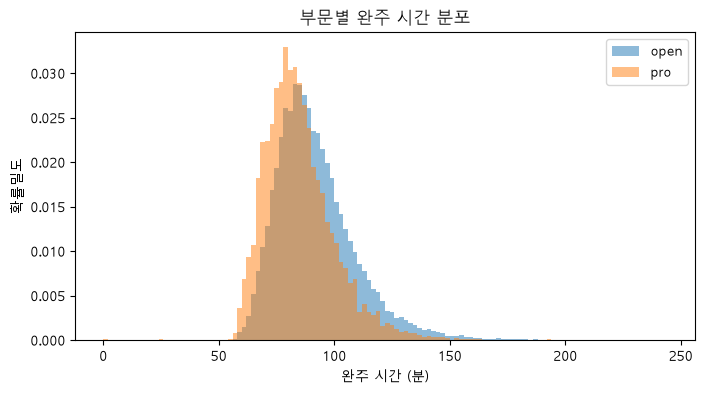

In [38]:
plt.figure(figsize=(8, 4))
for name, g in sub.groupby("division"):
    plt.hist(g["total_sec"] / 60, bins=range(0, 246, 2), alpha=0.5, density=True, label=name)  # 2분 간격, density: 부문별 기록 수 차이 보정
plt.xlabel("완주 시간 (분)")
plt.ylabel("확률밀도")
plt.title("부문별 완주 시간 분포")
plt.legend()
plt.show()

In [39]:
print((sub.groupby("division")["total_sec"].median() / 60).round(1).rename("완주 시간 중앙값(분)"))  # 단위: 분

division
open    89.0
pro     82.7
Name: 완주 시간 중앙값(분), dtype: float64


### 결과
- 완주 시간 중앙값 87.7분, 평균 90.6분 (평균 > 중앙값, 양의 왜도)
- 사분위수 78.8~99.4분, 표준편차 17.3분
- 최솟값 0분(0초 기록 8건), 최댓값 240.8분
- 부문별 기록 수: open 50,368건, pro 11,464건
- 부문별 중앙값: open 89.0분, pro 82.7분 (pro가 6.3분 빠름)
- 부문별 분포: pro가 빠른 쪽에 위치하고 봉우리가 높으며, open은 오른쪽 꼬리가 더 길고 두 분포는 넓게 중첩

### 추정·한계
- 0초 기록 8건은 이상값 후보이며, 원인(기록 누락, 입력 오류 등)과 최댓값 240.8분의 처리는 전처리 단계에서 확인
- 부문 차이의 원인(선수 수준 vs 부문 기준)은 이 결과만으로 구분 불가

### 한 줄 정리
- 완주 시간 평균은 90.6분이며, 부문별 중앙값은 open 89.0분, pro 82.7분으로 pro가 더 빠름

## 4. 구간별 기록 (런·스테이션·록스존)

**핵심:** 런·스테이션·록스존 구간별 중앙값을 비교하고 시간 비중이 큰 구간과 경기 진행에 따른 변화 경향 파악

### 작업 내용
- 대상 열: 런 `run_1~8`, 스테이션(운동 구간) `work_1~8`, 록스존 `roxzone_1~8` (1절에서 초 단위로 변환한 `_sec` 열 24개)
- 구간별 중앙값 계산
- 중앙값 사용 이유: 평균은 이상값(0초 기록 등)의 영향이 큼
- 표시 단위: 표는 분:초, 그래프는 분
- 구간 구성(HYROX 공개 규격 기준)
  - 런과 스테이션을 8회 반복
  - 록스존(roxzone): 런과 스테이션 사이의 전환 구간
  - 스테이션 순서: 1 스키에르그, 2 슬레드 푸시, 3 슬레드 풀, 4 버피 브로드 점프, 5 로잉, 6 파머스 캐리, 7 샌드백 런지, 8 월볼

### 확인 포인트
- 경기가 진행될수록 기록이 어떻게 변하는지
- 런·스테이션·록스존 중 시간 비중이 가장 큰 구간 유형이 무엇인지

구간별 중앙값 (분:초)


구간,런,스테이션,록스존
1,4:31,4:33,0:33
2,5:03,3:09,0:52
3,5:30,5:18,0:56
4,5:31,5:12,0:52
5,5:39,4:54,0:51
6,5:32,2:14,1:07
7,5:31,4:58,1:11
8,6:14,5:52,0:00


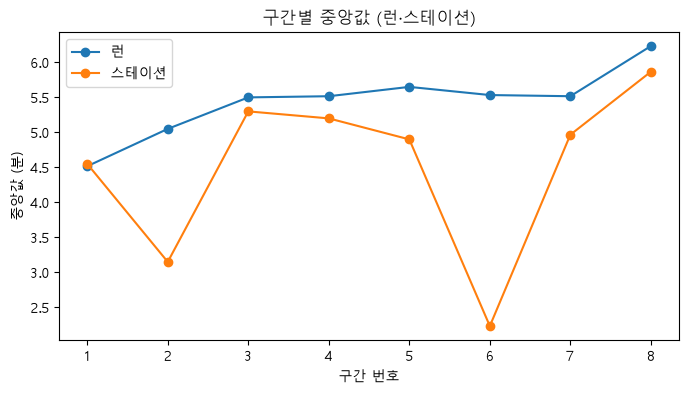

In [22]:
def to_mmss(sec):
    """초를 'm:ss' 형식으로 변환"""
    sec = int(round(sec))
    return f"{sec // 60}:{sec % 60:02d}"

med_sec = pd.DataFrame(
    {
        "런": [sub[f"run_{i}_sec"].median() for i in range(1, 9)],
        "스테이션": [sub[f"work_{i}_sec"].median() for i in range(1, 9)],  # 데이터의 work 열 = 스테이션
        "록스존": [sub[f"roxzone_{i}_sec"].median() for i in range(1, 9)],
    },
    index=range(1, 9),
)  # 행: 구간 번호, 값: 중앙값(초)

table = med_sec.map(to_mmss)
table = table.rename_axis(columns="구간")  # 헤더 행 왼쪽 칸에 '구간' 표시
print("구간별 중앙값 (분:초)")
display(table)

(med_sec[["런", "스테이션"]] / 60).plot(marker="o", figsize=(8, 4))  # 그래프는 분 단위 숫자로 표시
plt.xlabel("구간 번호")
plt.ylabel("중앙값 (분)")
plt.title("구간별 중앙값 (런·스테이션)")
plt.show()

In [23]:
print("구간 중앙값 합계 (분)")
print((med_sec.sum() / 60).round(1))
print("roxzone_8 최댓값(초):", sub["roxzone_8_sec"].max())  # 0이면 모든 기록이 0

구간 중앙값 합계 (분)
런       43.5
스테이션    36.2
록스존      6.4
dtype: float64
roxzone_8 최댓값(초): 0


### 결과
- 런 중앙값: 1구간 4:31 최단, 3~7구간 5:30~5:39로 유사, 8구간 6:14 최장
- 스테이션 중앙값: 6구간 2:14 최단, 8구간 5:52 최장
- 런 중앙값이 스테이션보다 큰 구간: 8개 중 7개 (1구간은 스테이션 4:33, 런 4:31)
- 록스존 중앙값: 1~7구간 0:33~1:11, 6·7구간에서 1분 이상
- 구간 중앙값 합계: 런 43.5분, 스테이션 36.2분, 록스존 6.4분

### 추정·한계
- 표의 8구간 록스존 0:00은 값이 없는 구간이며, 마지막 스테이션 뒤가 결승선이라는 경기 규격과 일치함. 이후 분석에서 `roxzone_8` 제외
- 스테이션 구간별 중앙값 차이는 종목 특성에 따른 것으로 추정 (구간 번호와 종목의 연결은 공개 규격 기준이며 데이터에 이름 열이 없음)
- 후반 런 기록 증가의 원인은 이 결과만으로 구분 불가 (피로 누적, 페이스 배분 방식, 직전 스테이션의 영향 등)
- 구간 중앙값의 합(약 86.1분)은 완주 시간 중앙값(87.7분)과 다른 값이며, 중앙값은 합산할 수 없음
- 구간 중앙값 합계는 open·pro 전체 기준이며, 부문이나 기록 수준에 따라 런·스테이션 비중이 달라질 수 있음 (기록별 비중은 03에서 확인)

### 한 줄 정리
- open·pro 전체 기준 구간 중앙값 합계는 런 43.5분, 스테이션 36.2분, 록스존 6.4분으로 런의 비중이 가장 큼